# 3. Calculus: derivatives, integrals, limits and series

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/notebooks/03_calculus.ipynb)

| Operation | Function |
| --- | --- |
| derivative, partial derivative | `sp.diff` |
| indefinite and definite integral | `sp.integrate` |
| limit | `sp.limit` |
| Taylor series | `sp.series` |

**Worked examples:** thermal expansion of a real gas, work of expansion, deflection of a
cantilever beam, the critical radius of insulation, and how good the small-angle approximation is.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## 3.1 Derivatives

**Example: how sensitive is a reaction rate to temperature?** For the Arrhenius law
$k = A\,e^{-E_a/(RT)}$, the relative sensitivity is $\dfrac{1}{k}\dfrac{dk}{dT}$.

In [2]:
A, Ea, R, T = sp.symbols("A E_a R T", positive=True)
k = A * sp.exp(-Ea / (R * T))

sensitivity = sp.simplify(sp.diff(k, T) / k)
sensitivity

 Eₐ 
────
   2
R⋅T 

In [3]:
# Ea = 80 kJ/mol at 350 K: the rate grows by about 8 % per kelvin
float(sensitivity.subs({Ea: 80e3, R: 8.314, T: 350}))

0.07854958196894346

### Partial derivatives of an equation of state

**Problem.** Find the thermal expansion coefficient
$\alpha = \dfrac{1}{V}\left(\dfrac{\partial V}{\partial T}\right)_P$ of a van der Waals gas.

**By hand.** The equation cannot be solved neatly for $V$, so use the cyclic rule:
$\left(\dfrac{\partial V}{\partial T}\right)_P = -\dfrac{(\partial P/\partial T)_V}{(\partial P/\partial V)_T}$.

In [4]:
V, a, b = sp.symbols("V a b", positive=True)
P_vdw = R * T / (V - b) - a / V**2

alpha = sp.simplify(-sp.diff(P_vdw, T) / sp.diff(P_vdw, V) / V)
alpha

       2             
    R⋅V ⋅(V - b)     
─────────────────────
     3              2
R⋅T⋅V  - 2⋅a⋅(V - b) 

**Verify** with the ideal-gas limit $a = b = 0$, where $\alpha$ must reduce to $1/T$.

In [5]:
assert sp.simplify(alpha.subs({a: 0, b: 0})) == 1 / T
sp.simplify(alpha.subs({a: 0, b: 0}))

1
─
T

## 3.2 Integrals

**Example: work of isothermal expansion.** $W = \displaystyle\int_{V_1}^{V_2} P\,dV$ for one
mole of ideal gas and of van der Waals gas.

In [6]:
V1, V2 = sp.symbols("V_1 V_2", positive=True)

W_ideal = sp.integrate(R * T / V, (V, V1, V2))
W_vdw = sp.integrate(P_vdw, (V, V1, V2), conds="none")
assert sp.simplify(W_ideal - R * T * sp.log(V2 / V1)) == 0      # the familiar RT ln(V2/V1)
W_ideal, W_vdw

⎛                                                                 a    a ⎞
⎜-R⋅T⋅log(V₁) + R⋅T⋅log(V₂), -R⋅T⋅log(V₁ - b) + R⋅T⋅log(V₂ - b) + ── - ──⎟
⎝                                                                 V₂   V₁⎠

`conds="none"` tells SymPy not to track the conditions for convergence (here $V > b$), which we
know hold physically.

**Example: centroid of a semicircular plate** of radius $R_0$, using a double integral in polar
coordinates: $\bar y = \dfrac{1}{A}\iint y\,dA$ with $y = r\sin\theta$ and $dA = r\,dr\,d\theta$.

In [7]:
r, theta, R0 = sp.symbols("r theta R_0", positive=True)

area = sp.integrate(r, (r, 0, R0), (theta, 0, sp.pi))
y_bar = sp.integrate(r * sp.sin(theta) * r, (r, 0, R0), (theta, 0, sp.pi)) / area
assert y_bar == 4 * R0 / (3 * sp.pi)
area, y_bar

⎛    2      ⎞
⎜π⋅R₀   4⋅R₀⎟
⎜─────, ────⎟
⎝  2    3⋅π ⎠

## 3.3 Worked example: deflection of a cantilever beam

**Problem.** A cantilever of length $L$ and bending stiffness $EI$ carries a uniform load $w$
per unit length. Find the deflection curve and the tip deflection.

**By hand.** Integrate $EI\,y'''' = -w$ four times, then fix the four constants from the
boundary conditions: $y(0) = 0$, $y'(0) = 0$ at the wall; $y''(L) = 0$, $y'''(L) = 0$
(no moment, no shear) at the free end.

In [8]:
x, L, w, E, I = sp.symbols("x L w E I", positive=True)
C1, C2, C3, C4 = sp.symbols("C1:5")

# four integrations of -w/(EI), each adding a constant
y = -w * x**4 / (24 * E * I) + C1 * x**3 / 6 + C2 * x**2 / 2 + C3 * x + C4

conditions = [
    y.subs(x, 0),                    # no deflection at the wall
    sp.diff(y, x).subs(x, 0),        # no slope at the wall
    sp.diff(y, x, 2).subs(x, L),     # no bending moment at the free end
    sp.diff(y, x, 3).subs(x, L),     # no shear force at the free end
]
constants = sp.solve(conditions, [C1, C2, C3, C4])
y_beam = sp.factor(y.subs(constants))
y_beam

    2 ⎛   2            2⎞ 
-w⋅x ⋅⎝6⋅L  - 4⋅L⋅x + x ⎠ 
──────────────────────────
          24⋅E⋅I          

**Verify** against the textbook tip deflection $-wL^4/(8EI)$, and check that the solution
satisfies the governing equation.

In [9]:
y_tip = y_beam.subs(x, L)
assert sp.simplify(y_tip + w * L**4 / (8 * E * I)) == 0
assert sp.simplify(E * I * sp.diff(y_beam, x, 4) + w) == 0
y_tip

  4   
-L ⋅w 
──────
8⋅E⋅I 

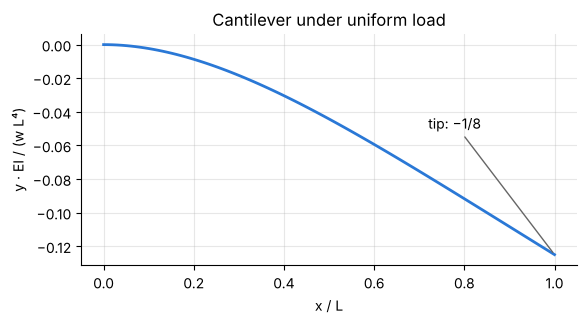

In [10]:
# dimensionless deflection curve: y / (w L^4 / EI) against x / L
xi = sp.symbols("xi")
shape = sp.simplify(y_beam.subs(x, xi * L) / (w * L**4 / (E * I)))
xs = np.linspace(0, 1, 100)

fig, ax = plt.subplots(figsize=(6.4, 3))
ax.plot(xs, sp.lambdify(xi, shape)(xs))
ax.set(xlabel="x / L", ylabel="y · EI / (w L⁴)", title="Cantilever under uniform load")
ax.annotate("tip: −1/8", xy=(1, -0.125), xytext=(0.72, -0.05), arrowprops={"arrowstyle": "-", "color": "0.4"});

## 3.4 Optimization: the critical radius of insulation

**Problem.** A pipe of outer radius $r_i$ is wrapped with insulation of conductivity $k$ out to
radius $r$; the outside heat-transfer coefficient is $h$. Adding insulation increases the
conduction resistance but also the outer surface area. Is there a worst thickness?

**By hand.** Total resistance per length $L$:
$R_{tot} = \dfrac{\ln(r/r_i)}{2\pi k L} + \dfrac{1}{2\pi r L h}$. Set $dR_{tot}/dr = 0$.

In [11]:
r, r_i, k_ins, h = sp.symbols("r r_i k h", positive=True)
R_tot = sp.log(r / r_i) / (2 * sp.pi * k_ins * L) + 1 / (2 * sp.pi * r * L * h)

r_crit = sp.solve(sp.diff(R_tot, r), r)[0]
curvature = sp.simplify(sp.diff(R_tot, r, 2).subs(r, r_crit))
r_crit, curvature

⎛       2   ⎞
⎜k     h    ⎟
⎜─, ────────⎟
⎜h         3⎟
⎝   2⋅π⋅L⋅k ⎠

The second derivative is positive, so $r = k/h$ is a **minimum** of resistance: insulating a thin
wire up to that radius *increases* the heat loss. For $k = 0.05$ W/(m·K) and $h = 10$ W/(m²·K)
the critical radius is 5 mm, which is why this matters for wires and small tubes but not for
large pipes.

In [12]:
assert r_crit == k_ins / h and curvature.is_positive

## 3.5 Limits

The efficiency of a straight fin with an insulated tip is $\eta = \dfrac{\tanh(mL)}{mL}$.
A very short or very conductive fin ($mL \to 0$) should be perfectly efficient, but direct
substitution gives $0/0$.

In [13]:
m = sp.symbols("m", positive=True)
eta = sp.tanh(m) / m          # m stands for the product mL
sp.limit(eta, m, 0), sp.limit(eta, m, sp.oo)

(1, 0)

## 3.6 Series: how good is an approximation?

A Taylor series turns a complicated expression into a simple one that is valid near a point,
and tells you the size of the first neglected term.

In [14]:
sp.series(eta, m, 0, 6)

     2      4        
    m    2⋅m     ⎛ 6⎞
1 - ── + ──── + O⎝m ⎠
    3     15         

So $\eta \approx 1 - (mL)^2/3$ for small $mL$.

**Example: the small-angle approximation** $\sin\theta \approx \theta$ used for pendulums and beams.

In [15]:
th = sp.symbols("theta")
sp.series(sp.sin(th), th, 0, 8)

     3    5      7         
    θ    θ      θ      ⎛ 8⎞
θ - ── + ─── - ──── + O⎝θ ⎠
    6    120   5040        

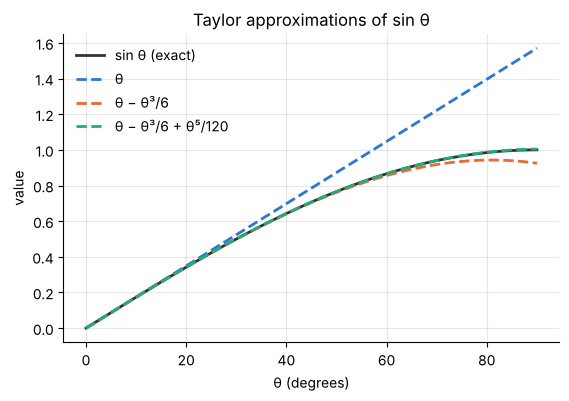

In [16]:
angles = np.linspace(0, np.pi / 2, 200)
fig, ax = plt.subplots()
ax.plot(np.degrees(angles), np.sin(angles), color="0.2", label="sin θ (exact)")
for order, name in ((2, "θ"), (4, "θ − θ³/6"), (6, "θ − θ³/6 + θ⁵/120")):
    approx = sp.series(sp.sin(th), th, 0, order).removeO()
    ax.plot(np.degrees(angles), sp.lambdify(th, approx)(angles), ls="--", label=name)
ax.set(xlabel="θ (degrees)", ylabel="value", title="Taylor approximations of sin θ")
ax.legend(frameon=False);

In [17]:
# relative error of sin θ ≈ θ at 10°, 20° and 30°
rel_err = (th - sp.sin(th)) / sp.sin(th)
[f"{deg}°: {float(rel_err.subs(th, sp.rad(deg))):.2%}" for deg in (10, 20, 30)]

['10°: 0.51%', '20°: 2.06%', '30°: 4.72%']

The error stays below 1 % up to about 14°, a useful number to remember.

## Exercises

1. Find the isothermal compressibility $\kappa_T = -\dfrac{1}{V}\left(\dfrac{\partial V}{\partial P}\right)_T$
   of a van der Waals gas and check the ideal-gas limit $1/P$.
2. Repeat 3.3 for a beam simply supported at both ends ($y = 0$ and $y'' = 0$ at $x = 0$ and
   $x = L$). The midspan deflection should be $-5wL^4/(384EI)$.
3. A closed cylindrical tank of fixed volume $V_0$ is to be made with the least sheet metal.
   Show that the optimum has height equal to diameter.
4. Expand $\dfrac{1}{1-x}$ and $\ln(1+x)$ up to and including the $x^4$ term (`n=5` in
   `sp.series`). Which familiar approximations do you recognize?
5. Compute the second moment of area of a rectangle $b \times h$ about its centroidal axis
   with a double integral.